In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [3]:
data=pd.read_excel('insurance_data.xlsx')

In [4]:
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
data.shape

(1338, 7)

In [6]:
#There are 1338 rows and 7 columns

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Three attributes sex,smoker,region are of type object(categorical)

In [8]:
data.isnull().values.any()

False

In [9]:
#five number summary
#min
#Q1
#Q2
#Q3
#max
data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='bmi', ylabel='Density'>

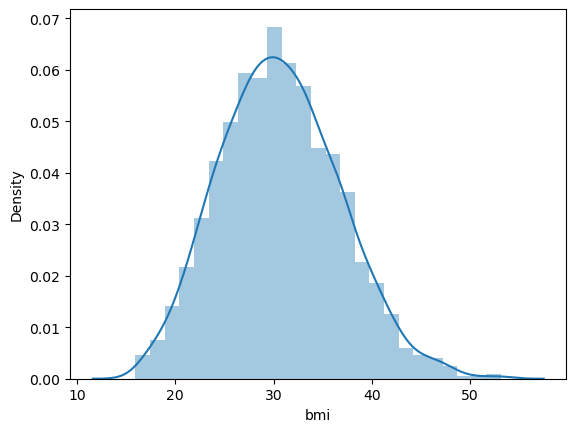

In [10]:
sns.distplot(data['bmi'])

C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='age', ylabel='Density'>

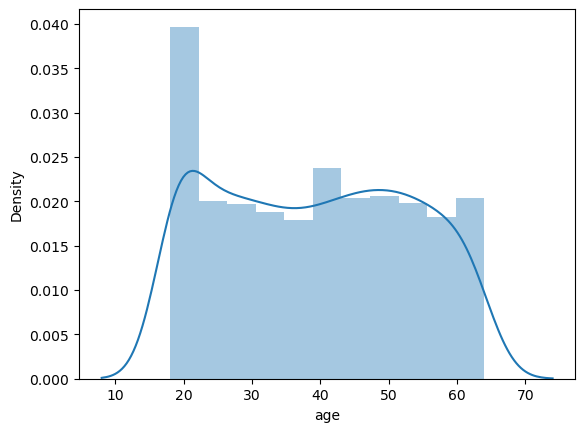

In [11]:
sns.distplot(data['age'])

C:\Users\Admin\anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='charges', ylabel='Density'>

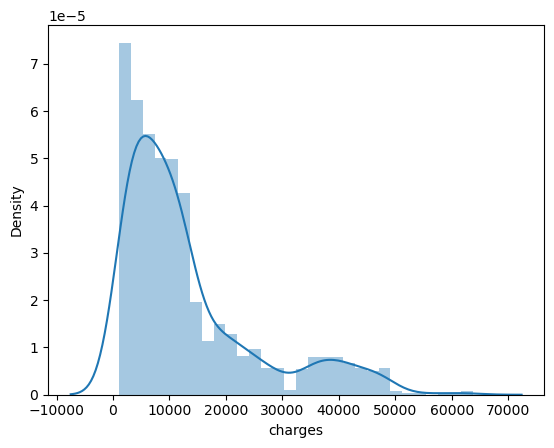

In [12]:
sns.distplot(data['charges'])

In [13]:
print("skewness of bmi:",stats.skew(data.bmi))
print("skewness of age:",stats.skew(data.age))
print("skewness of charges:",stats.skew(data.charges))

skewness of bmi: 0.28372857291709386
skewness of age: 0.055610083072599126
skewness of charges: 1.5141797118745743


<AxesSubplot:xlabel='bmi'>

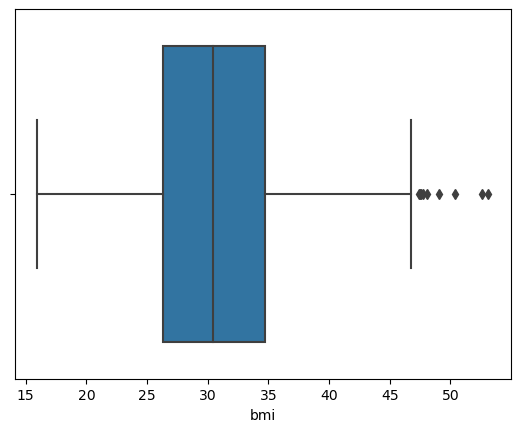

In [14]:
sns.boxplot(x=data['bmi'])

<AxesSubplot:xlabel='age'>

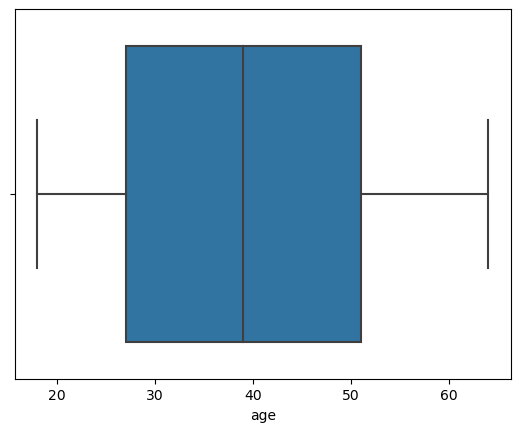

In [15]:
sns.boxplot(x=data['age'])

<AxesSubplot:xlabel='charges'>

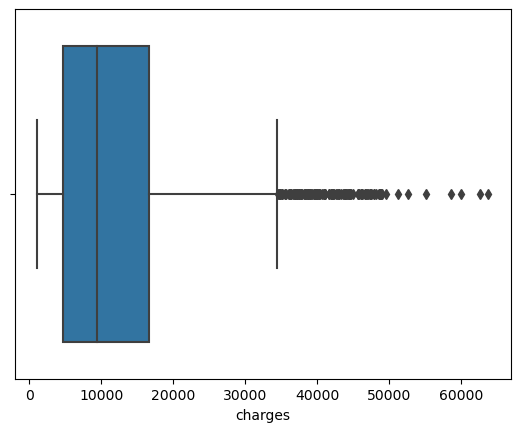

In [16]:
sns.boxplot(x=data['charges'])

<AxesSubplot:xlabel='children', ylabel='charges'>

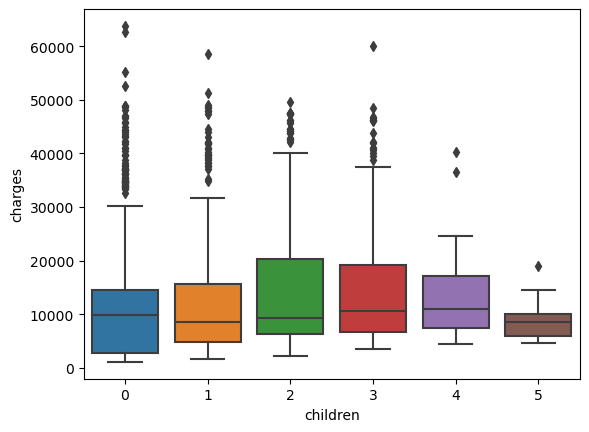

In [17]:
sns.boxplot(x='children',y='charges',data=data)

Extremely higher charges paid by people having no child.
least paid by people with 5 children

<AxesSubplot:xlabel='sex', ylabel='charges'>

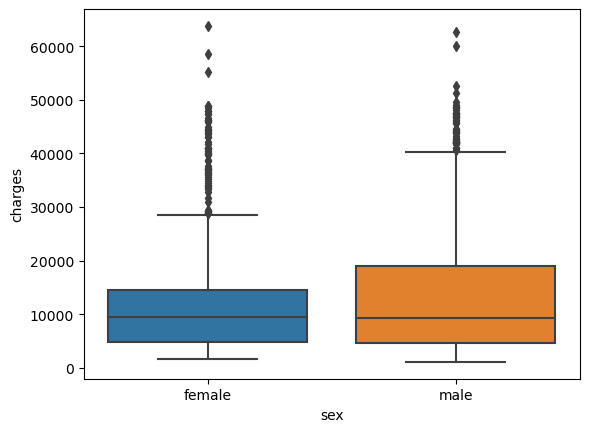

In [18]:
sns.boxplot(x='sex',y='charges',data=data)

<AxesSubplot:xlabel='region', ylabel='charges'>

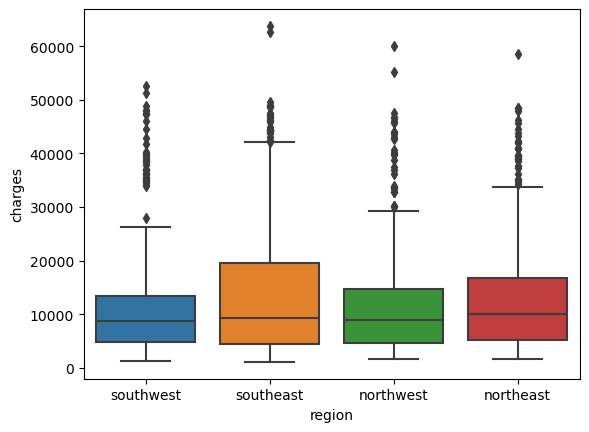

In [19]:
sns.boxplot(x='region',y='charges',data=data)

<AxesSubplot:xlabel='smoker', ylabel='charges'>

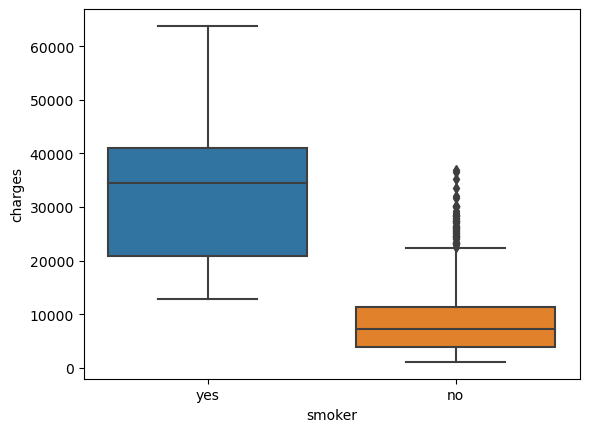

In [20]:
sns.boxplot(x='smoker',y='charges',data=data)

In [ ]:
#categorical data ----- numeric data
#label encoding
#one hot encoding

In [21]:
from sklearn.preprocessing import LabelEncoder

In [22]:
data_encoded=data
data_encoded.loc[:,['sex','smoker','region']]=data.loc[:,
                                                      ['sex',
                                                      'smoker',
                                                      'region']].apply(LabelEncoder().fit_transform)

In [30]:
data_encoded

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,3,16884.92400
1,18,1,33.770,1,0,2,1725.55230
2,28,1,33.000,3,0,2,4449.46200
3,33,1,22.705,0,0,1,21984.47061
4,32,1,28.880,0,0,1,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,1,10600.54830
1334,18,0,31.920,0,0,0,2205.98080
1335,18,0,36.850,0,0,2,1629.83350
1336,21,0,25.800,0,0,3,2007.94500


In [ ]:
#Do charges of people who smoke differ
#significantly from the people who dont

In [23]:
data.smoker.value_counts()

0    1064
1     274
Name: smoker, dtype: int64

In [24]:
Ha='''charges of smoker and non smoker are not the same'''
H0='''charges of smoker and non smoker are same'''

In [25]:
from scipy.stats import ttest_ind

In [28]:
x=np.array(data[data.smoker==1].charges)
y=np.array(data[data.smoker==0].charges)

In [29]:
test,p_value=ttest_ind(x,y)
alpha=0.05
if(p_value<=alpha):
    print("Reject H0")
else:
    print("Accept H0")

Reject H0


In [ ]:
#Does bmi of males differ significantly from that of females?

In [31]:
Ha='''Gender has an impact on bmi'''
H0='''Gender has no impact on bmi'''

In [32]:
x=np.array(data[data.sex==1].bmi)
y=np.array(data[data.sex==0].bmi)
test,p_value=ttest_ind(x,y)
if(p_value<=alpha):
    print("Reject H0")
else:
    print("Accept H0")

Accept H0


In [ ]:
'''Is the proportion of smokers significantly different
in different genders?'''

In [ ]:
import scipy.stats as stats
Ha='''Gender has an effect on smoking habits'''
H0='''Gender has no effect on smoking habits'''

In [33]:
c=pd.crosstab(data['sex'],data['smoker'])
test,p_value,dof,e=stats.chi2_contingency(c)
if(p_value<=alpha):
    print("Reject Ho")
else:
    print("Accept H0")

Reject Ho


In [ ]:
'''Is the distribution of bmi across women with no children,
one child and two children the same?'''

In [35]:
Ha='''No. of children has an effect on bmi'''
H0='No.of children has no effect on bmi'
female_data=data[data['sex']==0]
zero=female_data[female_data.children==0]['bmi']
one=female_data[female_data.children==1]['bmi']
two=female_data[female_data.children==2]['bmi']
test,p_value=stats.f_oneway(zero,one,two)
if(p_value<=alpha):
    print('Reject H0')
else:
    print("Accept H0")

Accept H0


In [ ]:
#Insurance charges show high variability and outliers
#BMI is not significantly influenced by gender
#smoking habits differ by gender
#No.of children does not affect bmi
#smoking inccreases medical charges
#highly paid was with zero child and least paid by 5 children